<a href="https://colab.research.google.com/github/yurireyes258/-metodos-/blob/main/EDA_resistencia_concreto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis Exploratorio de la Variable Objetivo: Resistencia a la compresión del concreto (MPa)

## 1. Importar librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

## 2. Cargar dataset

In [ ]:
df = pd.read_excel("Concrete_Data.xls")
df.columns = [
    "cemento", "escoria_alto_horno", "ceniza_volante", "agua",
    "superplastificante", "agregado_grueso", "agregado_fino",
    "edad_dias", "resistencia"
]
print("Filas, columnas:", df.shape)
display(df.head())

Filas, columnas: (1030, 9)


,cemento,escoria_alto_horno,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,resistencia
0,540.00,0.00,0.00,162.00,2.50,"1,040.00",676.00,28,79.99
1,540.00,0.00,0.00,162.00,2.50,"1,055.00",676.00,28,61.89
2,332.50,142.50,0.00,228.00,0.00,932.00,594.00,270,40.27
3,332.50,142.50,0.00,228.00,0.00,932.00,594.00,365,41.05
4,198.60,132.40,0.00,192.00,0.00,978.40,825.50,360,44.30


## 3. Variable target

In [ ]:
y = df["resistencia"]

print("Número de registros:", len(y))
print("Datos faltantes:", y.isnull().sum())
y.head()

Número de registros: 1030
Datos faltantes: 0


0   79.99
1   61.89
2   40.27
3   41.05
4   44.30
Name: resistencia, dtype: float64

## 4. Métricas estadísticas de la variable Y

In [ ]:
estadisticas = pd.DataFrame({
    "Estadístico": [
        "Media", "Mediana", "Desviación estándar", "Mínimo",
        "Primer cuartil (Q1)", "Tercer cuartil (Q3)", "Máximo"
    ],
    "Valor (MPa)": [
        y.mean(), y.median(), y.std(), y.min(),
        y.quantile(0.25), y.quantile(0.75), y.max()
    ]
})

estadisticas.round(2)

,Estadístico,Valor (MPa)
0,Media,35.82
1,Mediana,34.44
2,Desviación estándar,16.71
3,Mínimo,2.33
4,Primer cuartil (Q1),23.71
5,Tercer cuartil (Q3),46.14
6,Máximo,82.60


## 5. Distribución de la variable Y

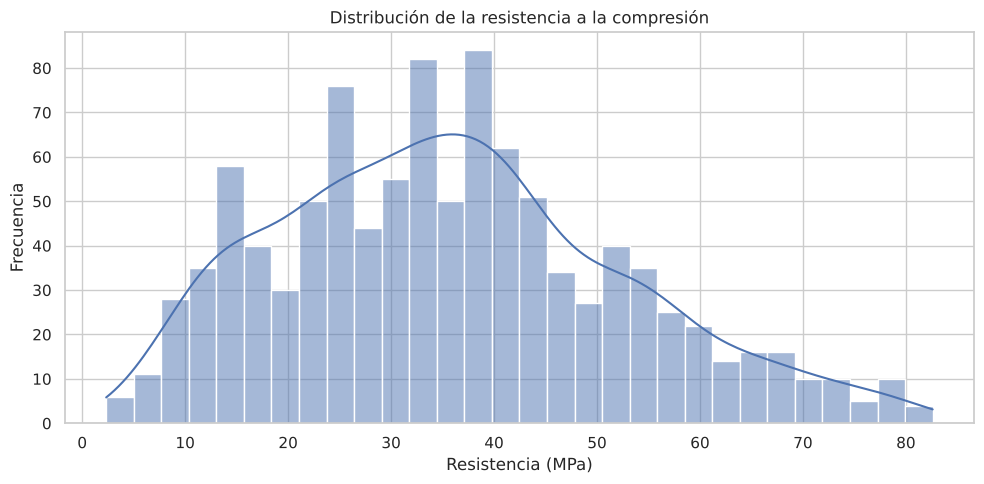

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(y, bins=30, kde=True)

plt.title("Distribución de la resistencia a la compresión")
plt.xlabel("Resistencia (MPa)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

## 6. Valores atípicos

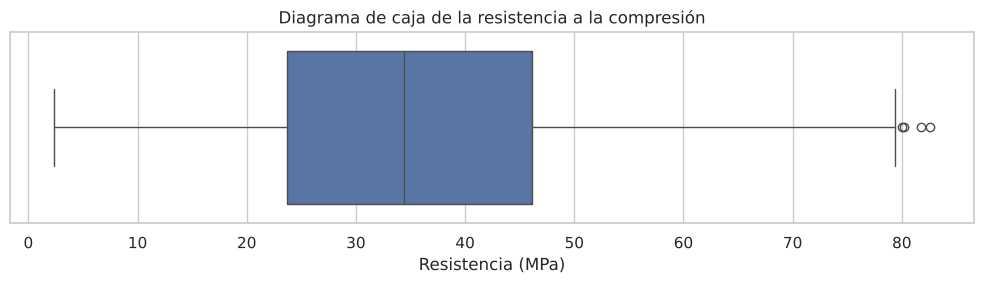

In [ ]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=y)
plt.title("Diagrama de caja de la resistencia a la compresión")
plt.xlabel("Resistencia (MPa)")
plt.tight_layout()
plt.show()

In [ ]:
Q1, Q3 = y.quantile(0.25), y.quantile(0.75)
IQR = Q3 - Q1
outliers = y[(y < Q1 - 1.5 * IQR) | (y > Q3 + 1.5 * IQR)]
print(f"Valores atípicos según regla de 1.5·IQR: {len(outliers)} ({len(outliers)/len(y):.1%})")

Valores atípicos según regla de 1.5·IQR: 4 (0.4%)


## 7. Asimetría y curtosis de la variable

In [ ]:
print("Asimetría:", round(y.skew(), 3))
print("Curtosis:", round(y.kurtosis(), 3))

Asimetría: 0.417
Curtosis: -0.314


## 8. Revisión de duplicados

In [ ]:
print("Filas duplicadas:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Filas duplicadas:", df.duplicated().sum())


Filas duplicadas: 25
Filas duplicadas: 0


## 9. Diagramas de dispersión: target vs variables numéricas

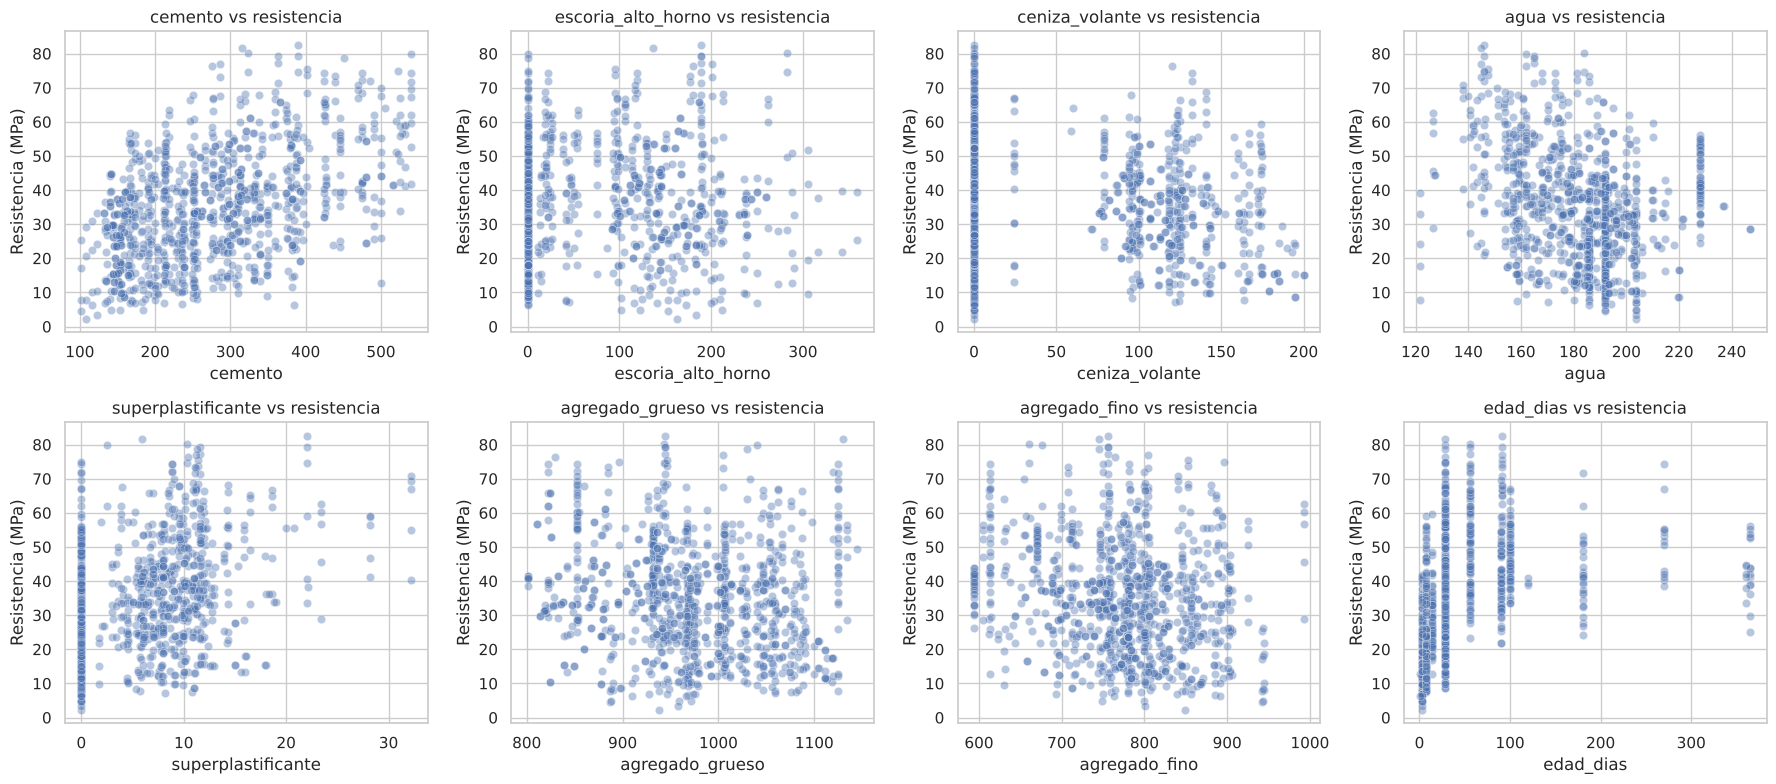

In [ ]:
predictoras = [c for c in df.columns if c != "resistencia"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flatten(), predictoras):
    sns.scatterplot(x=df[col], y=df["resistencia"], alpha=0.4, ax=ax)
    ax.set_title(f"{col} vs resistencia")
    ax.set_xlabel(col)
    ax.set_ylabel("Resistencia (MPa)")

plt.tight_layout()
plt.show()

## 10. Correlaciones

In [ ]:

corr = df.corr()


print("Correlación de cada variable con la resistencia (ordenada):")
corr["resistencia"].drop("resistencia").sort_values(ascending=False).round(3)

Correlación de cada variable con la resistencia (ordenada):


cemento               0.49
superplastificante    0.34
edad_dias             0.34
escoria_alto_horno    0.10
ceniza_volante       -0.08
agregado_grueso      -0.14
agregado_fino        -0.19
agua                 -0.27
Name: resistencia, dtype: float64

## 11. Estandarización de X

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separar X (predictoras) y y (target)
X = df.drop(columns="resistencia")
y = df["resistencia"]

# 2. Separar train y test ANTES de estandarizar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# 3. Ajustar el escalador solo con train y transformar ambos
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X.columns, index=X_test.index
)

# 4. Verificar: media ≈ 0 y desviación estándar ≈ 1 en train
display(X_train_scaled.describe().T[["mean", "std"]].round(3))

,mean,std
cemento,-0.00,1.00
escoria_alto_horno,-0.00,1.00
ceniza_volante,0.00,1.00
agua,-0.00,1.00
superplastificante,0.00,1.00
agregado_grueso,-0.00,1.00
agregado_fino,-0.00,1.00
edad_dias,-0.00,1.00


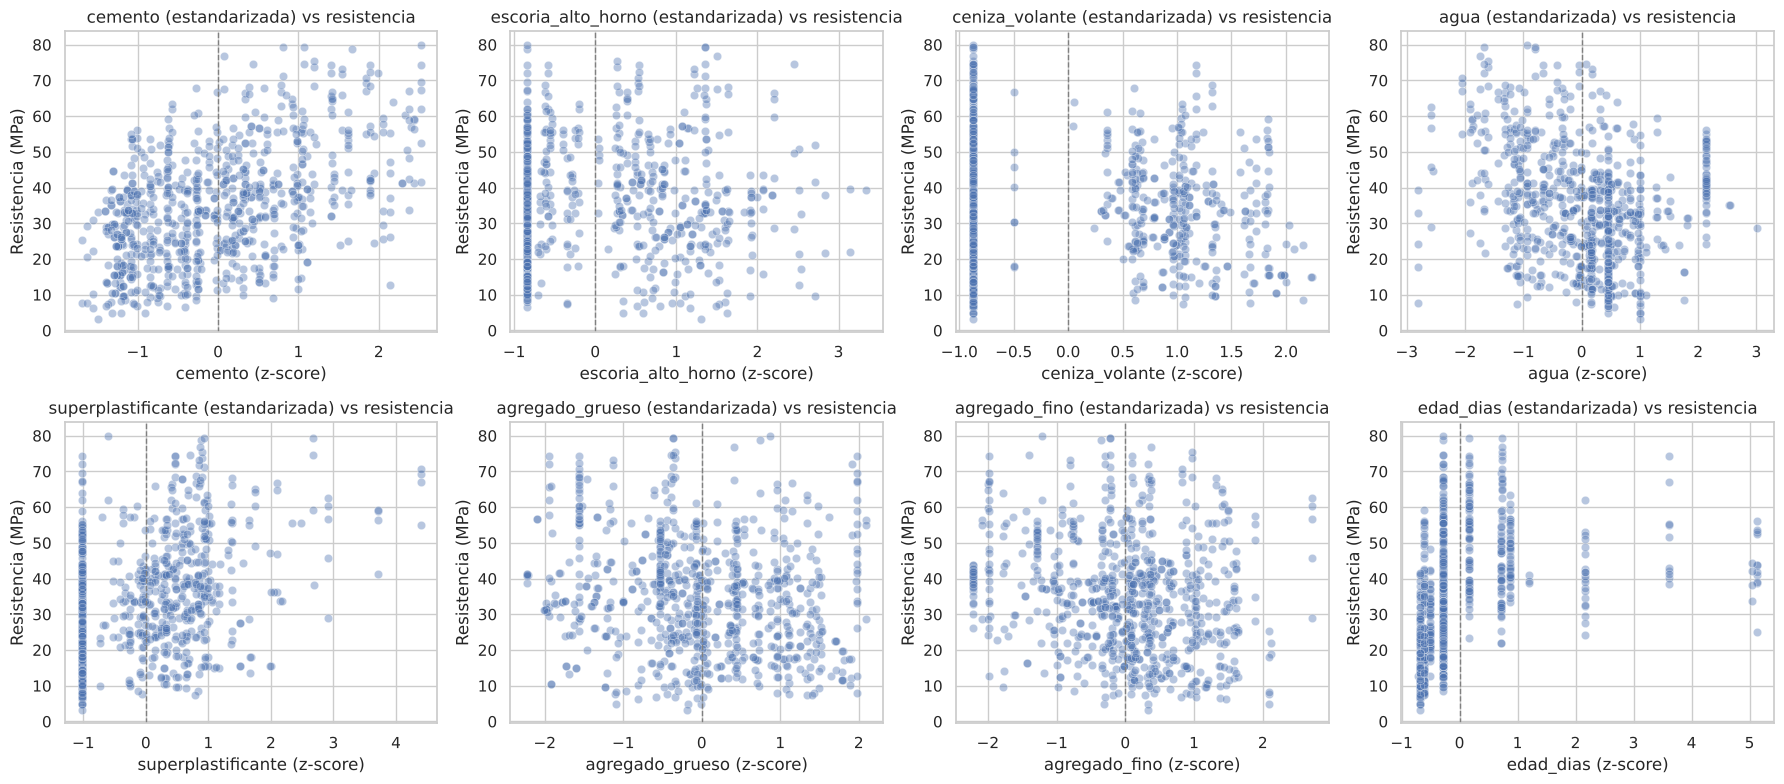

In [ ]:
predictoras = X_train_scaled.columns

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flatten(), predictoras):
    sns.scatterplot(x=X_train_scaled[col], y=y_train, alpha=0.4, ax=ax)
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)  # referencia: media = 0
    ax.set_title(f"{col} (estandarizada) vs resistencia")
    ax.set_xlabel(f"{col} (z-score)")
    ax.set_ylabel("Resistencia (MPa)")

plt.tight_layout()
plt.show()

# MODELO SIN ESTANDARIZAR

In [ ]:
import statsmodels.api as sm


In [ ]:
print(" la X_train tiene:", X_train.shape)
print(" la X_test tiene:", X_test.shape)

 la X_train tiene: (804, 8)
 la X_test tiene: (201, 8)


In [ ]:
# Se agrega una columna de unos (const) a X_train para que el modelo incluya el intercepto β₀.
# statsmodels no lo agrega automáticamente; sin esta columna el modelo pasaría por el origen.
X_train_const = sm.add_constant(X_train)
X_train_const.head()

,const,cemento,escoria_alto_horno,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias
78,1.00,531.30,0.00,0.00,141.80,28.20,852.10,893.70,3
29,1.00,475.00,0.00,0.00,228.00,0.00,932.00,594.00,7
280,1.00,277.10,0.00,97.40,160.60,11.80,973.90,875.60,3
507,1.00,436.00,0.00,0.00,218.00,0.00,838.40,719.70,28
652,1.00,166.80,250.20,0.00,203.50,0.00,975.60,692.60,7


In [ ]:
#creo formula
modelo = sm.OLS(y_train,X_train_const)

resultado = modelo.fit()


resultado.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            resistencia   R-squared:                       0.610
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                     155.3
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          7.79e-157
Time:                        19:34:32   Log-Likelihood:                -2992.2
No. Observations:                 804   AIC:                             6002.
Df Residuals:                     795   BIC:                             6045.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                -23.3893     28.869     -0.810      0.418     -80.058      33.279
cemento                0.1167      0.009     12.811      0.000       0.099       0.135
escoria_alto_horno     0.0981      0.011      8.864      0.000       0.076       0.120
ceniza_volante         0.0846      0.014      6.234      0.000       0.058       0.111
agua                  -0.1314      0.043     -3.025      0.003      -0.217      -0.046
superplastificante     0.3315      0.102      3.255      0.001       0.132       0.531
agregado_grueso        0.0155      0.010      1.514      0.130      -0.005       0.036
agregado_fino          0.0206      0.012      1.770      0.077      -0.002       0.044
edad_dias              0.1106      0.006     18.248      0.000       0.099       0.123
==============================================================================
Omnibus:                        3.189   Durbin-Watson:                   1.995
Prob(Omnibus):                  0.203   Jarque-Bera (JB):                3.105
Skew:                          -0.151   Prob(JB):                        0.212
Kurtosis:                       3.032   Cond. No.                     1.05e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.05e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
#r-stdent

r_student = resultado.get_influence().resid_studentized_external
print(r_student[:5])


[-2.02944669  0.9063537  -1.03415467 -0.59737773 -0.83266225]


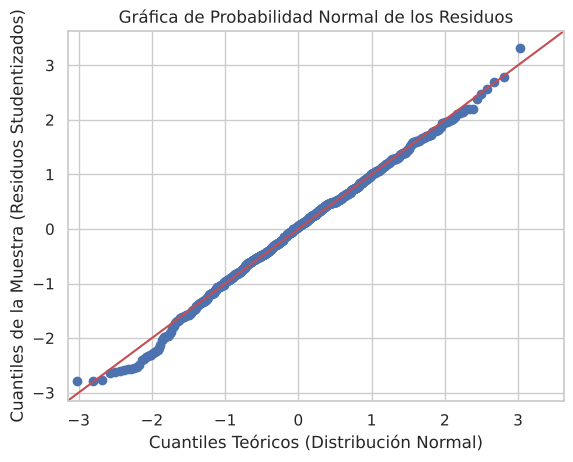

In [ ]:
fig = sm.qqplot(r_student, line='45')

# 3. Personalizas los títulos y etiquetas
plt.title("Gráfica de Probabilidad Normal de los Residuos")
plt.xlabel("Cuantiles Teóricos (Distribución Normal)")
plt.ylabel("Cuantiles de la Muestra (Residuos Studentizados)")
plt.grid(True)

# 4. Muestras la gráfica
plt.show()

La gráfica de probabilidad normal de los R-student muestra puntos cercanos a la línea recta, con desviaciones leves en las colas y un posible outlier cercano a 3.3. Se considera satisfactoria la normalidad (fig. 4.3a). Se revisará la influencia del punto extremo más adelante (sec. 4.4).

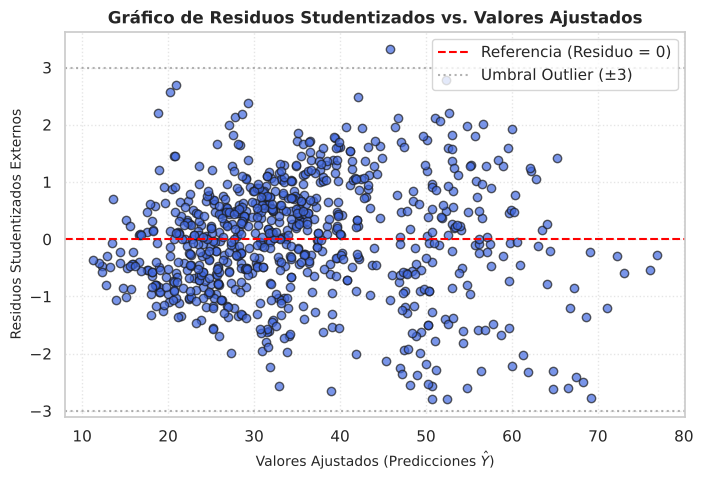

In [ ]:

# 1. Obtener los valores ajustados (predichos por el modelo)
valores_ajustados = resultado.fittedvalues



# 3. Crear el gráfico de dispersión (Scatter Plot)
plt.figure(figsize=(8, 5))
plt.scatter(valores_ajustados, r_student, color='royalblue', edgecolor='k', alpha=0.7)

# 4. Dibujar la línea horizontal de referencia en 0
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Referencia (Residuo = 0)')

# 5. Agregar líneas guía opcionales para detectar Outliers (>3 o <-3)
plt.axhline(y=3, color='gray', linestyle=':', alpha=0.6, label='Umbral Outlier (±3)')
plt.axhline(y=-3, color='gray', linestyle=':', alpha=0.6)

# 6. Configurar etiquetas, títulos y diseño
plt.title("Gráfico de Residuos Studentizados vs. Valores Ajustados", fontsize=12, fontweight='bold')
plt.xlabel(r"Valores Ajustados (Predicciones $\hat{Y}$)", fontsize=10)
plt.ylabel("Residuos Studentizados Externos", fontsize=10)
plt.legend(loc='best')

# --- CORREGIDO AQUÍ: Usamos ':' para la cuadrícula y alpha por separado ---
plt.grid(True, linestyle=':', alpha=0.5)

# 7. Mostrar la gráfica por separado
plt.show()


Q-Q plot: verifica normalidad. Residuos vs ajustados: verifica varianza constante y linealidad.

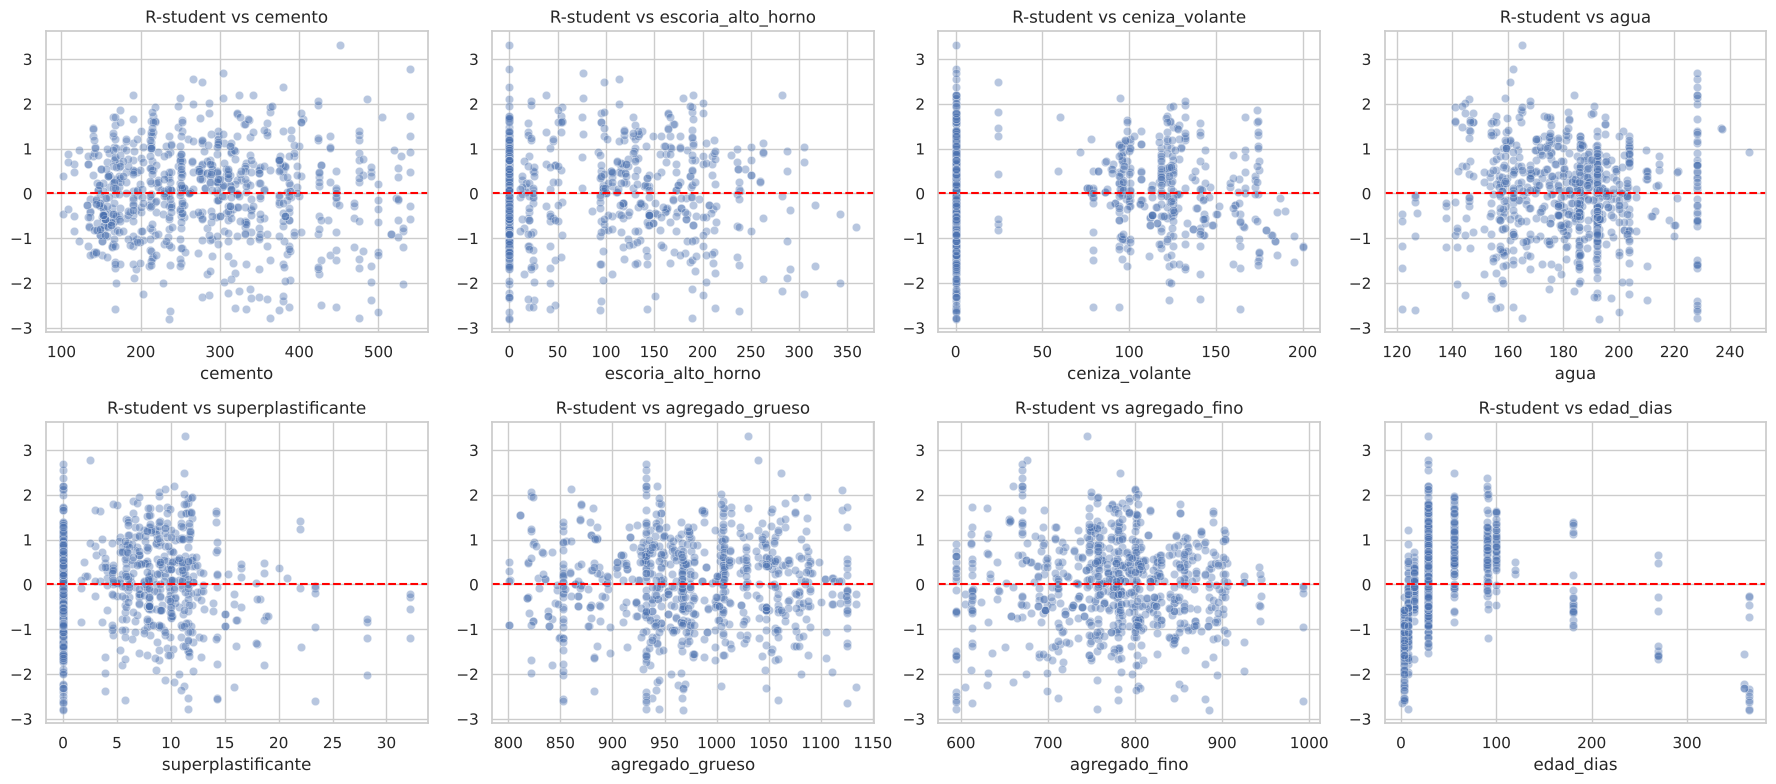

In [ ]:

rstudent = resultado.get_influence().resid_studentized_external
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flatten(), X_train.columns):
    sns.scatterplot(x=X_train[col], y=rstudent, alpha=0.4, ax=ax)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"R-student vs {col}")

plt.tight_layout()
plt.show()

### Residuos vs. cada variable

Aquí graficamos los residuos del modelo contra cada una de las 8 variables, para ver si alguna no tiene una relación lineal con la resistencia. Lo ideal es que los puntos queden en una banda horizontal alrededor de cero, sin ninguna forma.

Lo que vimos es que `edad_dias` sí tiene un patrón claro: con edades cortas (1 a 7 días) los residuos son negativos, entre 28 y 90 días son positivos, y con edades largas (270 a 365 días) vuelven a ser negativos. Esto forma una curva, o sea que la relación entre la edad y la resistencia no es una línea recta: el concreto gana resistencia rápido al principio y luego se va aplanando.

Las demás variables se ven bastante bien. En escoria, ceniza volante y superplastificante hay muchos puntos en 0 porque varias mezclas no llevan ese ingrediente, pero no se ve una curva.

Por eso el siguiente paso es transformar `edad_dias`, empezando con el logaritmo, y comparar el resultado con el modelo base.

In [ ]:
#atipicos
### Posibles outliers

#Contamos cuántas observaciones tienen un R-student mayor a 3 en valor absoluto, que es el criterio que usa el libro para marcar un posible outlier.
atipicos = np.abs(rstudent) > 3

print("Posibles outliers (|R-student| > 3):", atipicos.sum())
print(f"Porcentaje: {atipicos.mean():.1%}")

X_train[atipicos]

Posibles outliers (|R-student| > 3): 1
Porcentaje: 0.1%


,cemento,escoria_alto_horno,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias
359,451.00,0.00,0.00,165.00,11.30,"1,030.00",745.00,28


In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan


lm, lm_pvalor, f, f_pvalor = het_breuschpagan(resultado.resid, X_train_const)

print("Estadístico LM:", round(lm, 3))
print("p-valor (LM):", lm_pvalor)
print("p-valor (F):", f_pvalor)

Estadístico LM: 91.314
p-valor (LM): 2.515190593737999e-16
p-valor (F): 2.5450906308941902e-17


### Prueba de Breusch-Pagan

Sirve para confirmar si la varianza de los errores es constante (hipótesis nula). El p-valor salió de 2.5e-16, mucho menor a 0.05, así que se rechaza la hipótesis nula: **hay varianza no constante**. Esto confirma el embudo que se veía en la gráfica de residuos vs. valores ajustados y sugiere probar una transformación sobre y

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def metricas(y_real, y_pred, nombre):
    return {
        "Modelo": nombre,
        "R²": r2_score(y_real, y_pred),
        "RMSE (MPa)": np.sqrt(mean_squared_error(y_real, y_pred)),
        "MAE (MPa)": mean_absolute_error(y_real, y_pred),
    }

X_test_const = sm.add_constant(X_test)
pred_test = resultado.predict(X_test_const)

tabla_resultados = pd.DataFrame([metricas(y_test, pred_test, "Modelo 1: sin estandarizar")])
tabla_resultados.round(3)

,Modelo,R²,RMSE (MPa),MAE (MPa)
0,Modelo 1: sin estandarizar,0.58,11.19,8.89


### Evaluación del Modelo 1 en test

En los datos de prueba el modelo obtuvo R² = 0.58, RMSE = 11.19 MPa y MAE = 8.90 MPa. El R² es parecido al de entrenamiento (0.61), así que no hay sobreajuste, pero el error promedio es de unos 9 MPa. Estos valores son la referencia para comparar los demás modelos.

## Modelo 2: regresión múltiple estandarizada

In [ ]:
X_train_scaled_const = sm.add_constant(X_train_scaled)
X_train_scaled_const.head()

,const,cemento,escoria_alto_horno,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias
78,1.00,2.44,-0.84,-0.88,-1.87,3.72,-1.56,1.49,-0.68
29,1.00,1.89,-0.84,-0.88,2.13,-1.02,-0.53,-2.22,-0.61
280,1.00,-0.01,-0.84,0.64,-1.00,0.96,0.02,1.26,-0.68
507,1.00,1.52,-0.84,-0.88,1.67,-1.02,-1.74,-0.66,-0.28
652,1.00,-1.07,2.07,-0.88,0.99,-1.02,0.04,-1.00,-0.61


In [ ]:
modelo = sm.OLS(y_train,X_train_scaled_const)

resultado_scaled = modelo.fit()


resultado_scaled.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            resistencia   R-squared:                       0.610
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                     155.3
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          7.79e-157
Time:                        19:34:35   Log-Likelihood:                -2992.2
No. Observations:                 804   AIC:                             6002.
Df Residuals:                     795   BIC:                             6045.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 35.0670      0.355     98.856      0.000      34.371      35.763
cemento               12.1188      0.946     12.811      0.000      10.262      13.976
escoria_alto_horno     8.4373      0.952      8.864      0.000       6.569      10.306
ceniza_volante         5.4395      0.873      6.234      0.000       3.727       7.152
agua                  -2.8279      0.935     -3.025      0.003      -4.663      -0.993
superplastificante     1.9708      0.605      3.255      0.001       0.782       3.159
agregado_grueso        1.1990      0.792      1.514      0.130      -0.356       2.754
agregado_fino          1.6699      0.943      1.770      0.077      -0.182       3.522
edad_dias              6.8945      0.378     18.248      0.000       6.153       7.636
==============================================================================
Omnibus:                        3.189   Durbin-Watson:                   1.995
Prob(Omnibus):                  0.203   Jarque-Bera (JB):                3.105
Skew:                          -0.151   Prob(JB):                        0.212
Kurtosis:                       3.032   Cond. No.                         8.78
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
y_train.mean()

np.float64(35.066977611940295)

In [ ]:
np.allclose(resultado.resid, resultado_scaled.resid)

True

In [ ]:

X_test_scaled_const = sm.add_constant(X_test_scaled)
pred_test_scaled = resultado_scaled.predict(X_test_scaled_const)

fila = pd.DataFrame([metricas(y_test, pred_test_scaled, "Modelo 2: estandarizado")])
tabla_resultados = pd.concat([tabla_resultados, fila], ignore_index=True)

tabla_resultados.round(3)

,Modelo,R²,RMSE (MPa),MAE (MPa)
0,Modelo 1: sin estandarizar,0.58,11.19,8.89
1,Modelo 2: estandarizado,0.58,11.19,8.89


In [ ]:
tabla_resultados = tabla_resultados.drop_duplicates(subset="Modelo").reset_index(drop=True)
tabla_resultados.round(3)

,Modelo,R²,RMSE (MPa),MAE (MPa)
0,Modelo 1: sin estandarizar,0.58,11.19,8.89
1,Modelo 2: estandarizado,0.58,11.19,8.89


## Modelo 2: regresión múltiple estandarizada

Se ajustó la misma regresión con las variables estandarizadas (`X_train_scaled`).

**Lo que no cambió:** el R² (0.610), los valores t y p de cada variable, y las pruebas sobre los residuos (Durbin-Watson, Omnibus, Jarque-Bera). Las métricas en test son iguales a las del Modelo 1 (R² = 0.58, RMSE = 11.19 MPa, MAE = 8.90 MPa). Estandarizar solo cambia la escala de las variables, no las predicciones.

**Lo que sí cambió:**
- **Intercepto:** pasó de -23.2 a 35.07, que es el promedio de la resistencia en entrenamiento.
- **Coeficientes:** ahora indican los MPa que cambia la resistencia por cada desviación estándar de la variable, así que se pueden comparar entre sí. Las de mayor efecto son cemento, escoria y edad.
- **Número de condición:** bajó de 1.05e5 a 8.78. El aviso de multicolinealidad del Modelo 1 se debía a la escala de las variables.

**Conclusión:** los dos modelos son equivalentes en ajuste y predicción. Como los residuos son los mismos, el diagnóstico del Modelo 1 (varianza no constante y curvatura en `edad_dias`) también aplica aquí.

## Transformaciones sobre las x

In [ ]:


X_train_log = X_train.assign(edad_dias=np.log(X_train["edad_dias"])).rename(columns={"edad_dias": "log_edad_dias"})
X_test_log = X_test.assign(edad_dias=np.log(X_test["edad_dias"])).rename(columns={"edad_dias": "log_edad_dias"})

# Se estandariza después del log, ajustando el escalador solo con train
scaler_log = StandardScaler()
X_train_log_scaled = pd.DataFrame(scaler_log.fit_transform(X_train_log), columns=X_train_log.columns, index=X_train_log.index)
X_test_log_scaled = pd.DataFrame(scaler_log.transform(X_test_log), columns=X_test_log.columns, index=X_test_log.index)


print(X_train_log_scaled.mean().round(2).values)
print(X_train_log_scaled.std().round(2).values)

[-0. -0.  0. -0.  0. -0. -0.  0.]
[1. 1. 1. 1. 1. 1. 1. 1.]


### Log de edad_dias

En los residuos se vio que `edad_dias` tiene una relación curva con la resistencia: el concreto gana resistencia rápido al principio y luego se aplana. Por eso se le aplica el logaritmo (sec. 5.3 del libro). Después se vuelve a estandarizar, con el escalador ajustado solo con train.

In [ ]:
X_train_log_const = sm.add_constant(X_train_log_scaled)
resultado_log = sm.OLS(y_train, X_train_log_const).fit()

resultado_log.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            resistencia   R-squared:                       0.813
Model:                            OLS   Adj. R-squared:                  0.811
Method:                 Least Squares   F-statistic:                     432.8
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          1.20e-283
Time:                        19:34:35   Log-Likelihood:                -2696.1
No. Observations:                 804   AIC:                             5410.
Df Residuals:                     795   BIC:                             5452.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 35.0670      0.245    142.885      0.000      34.585      35.549
cemento               13.6583      0.657     20.803      0.000      12.370      14.947
escoria_alto_horno     9.5248      0.658     14.471      0.000       8.233      10.817
ceniza_volante         5.9828      0.602      9.940      0.000       4.801       7.164
agua                  -2.5494      0.646     -3.944      0.000      -3.818      -1.281
superplastificante     0.7406      0.421      1.761      0.079      -0.085       1.566
agregado_grueso        2.1274      0.549      3.877      0.000       1.050       3.205
agregado_fino          2.7959      0.653      4.282      0.000       1.514       4.078
log_edad_dias         10.0059      0.253     39.516      0.000       9.509      10.503
==============================================================================
Omnibus:                       17.391   Durbin-Watson:                   1.909
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               20.042
Skew:                           0.286   Prob(JB):                     4.45e-05
Kurtosis:                       3.521   Cond. No.                         8.60
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Resultado del Modelo 3: log de edad_dias

Con el logaritmo de la edad, el R² sube de 0.610 a 0.813 y el AIC baja de 6003 a 5410, una mejora grande. `log_edad_dias` es la variable más predictiva (t = 39.5). Los agregados pasan a ser significativos y `superplastificante` deja de serlo (p = 0.082). Las pruebas de normalidad de los residuos ahora rechazan la normalidad (Jarque-Bera p ≈ 4.5e-05), por lo que se revisa con las gráficas.

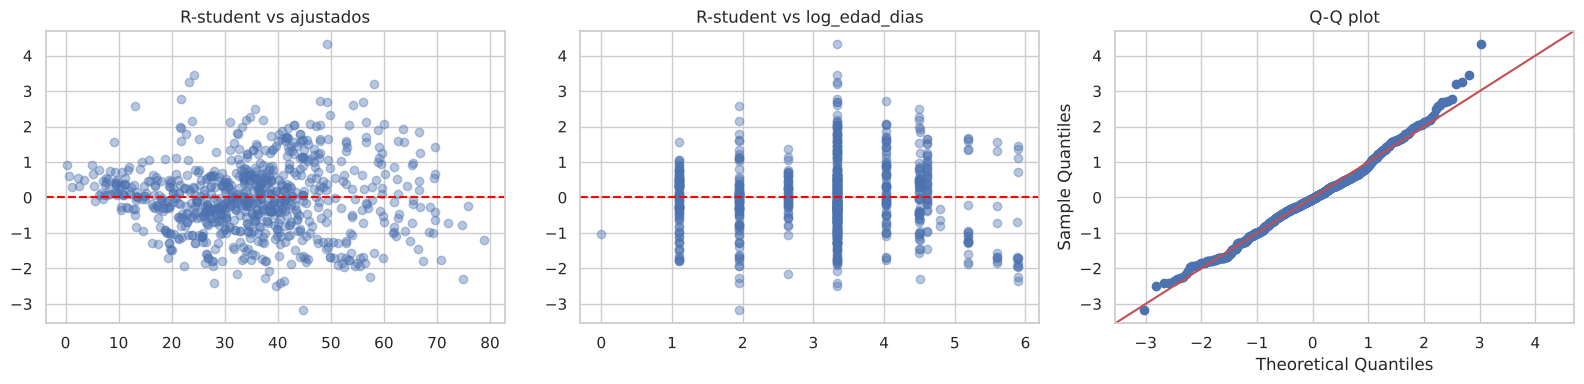

Breusch-Pagan p-valor: 1.8774377136155435e-12


In [ ]:


rstudent_log = resultado_log.get_influence().resid_studentized_external

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(resultado_log.fittedvalues, rstudent_log, alpha=0.4)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("R-student vs ajustados")

axes[1].scatter(X_train_log["log_edad_dias"], rstudent_log, alpha=0.4)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("R-student vs log_edad_dias")

sm.qqplot(rstudent_log, line="45", ax=axes[2])
axes[2].set_title("Q-Q plot")

plt.tight_layout()
plt.show()

print("Breusch-Pagan p-valor:", het_breuschpagan(resultado_log.resid, X_train_log_const)[1])

### Diagnóstico del Modelo 3

Con el log de `edad_dias` desapareció la curvatura en los residuos: ya no se ve la forma de U invertida contra la edad. Siguen dos problemas: la varianza no es constante (Breusch-Pagan p = 1.9e-12) y la cola derecha del Q-Q plot se separa de la línea, lo que explica el rechazo de normalidad. Ambos se atacan transformando y (sec. 5.2 del libro), que se hará en la siguiente parte.

In [ ]:
X_test_log_const = sm.add_constant(X_test_log_scaled)
pred_test_log = resultado_log.predict(X_test_log_const)

fila = pd.DataFrame([metricas(y_test, pred_test_log, "Modelo 3: log edad (estandarizado)")])
tabla_resultados = pd.concat([tabla_resultados, fila], ignore_index=True)
tabla_resultados = tabla_resultados.drop_duplicates(subset="Modelo").reset_index(drop=True)

print("Posibles outliers (|R-student| > 3):", (np.abs(rstudent_log) > 3).sum())
tabla_resultados.round(3)

Posibles outliers (|R-student| > 3): 5


,Modelo,R²,RMSE (MPa),MAE (MPa)
0,Modelo 1: sin estandarizar,0.58,11.19,8.89
1,Modelo 2: estandarizado,0.58,11.19,8.89
2,Modelo 3: log edad (estandarizado),0.80,7.65,5.84


### Evaluación del Modelo 3 en test

Con el log de `edad_dias`, el R² en test sube de 0.58 a 0.80, el RMSE baja de 11.19 a 7.65 MPa y el MAE de 8.90 a 5.84 MPa. El R² es parecido al de entrenamiento (0.81), así que no hay sobreajuste. Se detectaron 5 posibles outliers (|R-student| > 3, 0.6% de los datos); no se eliminan.

In [ ]:
X_train_mejor = X_train_log_scaled
X_test_mejor = X_test_log_scaled

print(X_train_mejor.shape, X_test_mejor.shape)


(804, 8) (201, 8)


## Transformación de y

Al Modelo 3 le quedaban dos problemas: Breusch-Pagan sigue rechazando (varianza no constante, el embudo en R-student vs ajustados) y en el Q-Q plot la cola derecha se separa de la línea. Esto se ataca transformando y. Desde aquí usamos `X_train_mejor` y `X_test_mejor` (las X del Modelo 3: log de la edad y estandarizadas).

Para escoger la transformación usamos Box-Cox (sec. 5.4.1 del libro): se ajusta el modelo con y^λ para varios valores de λ y nos quedamos con el que da menor SSRes.

λ óptimo: 0.6


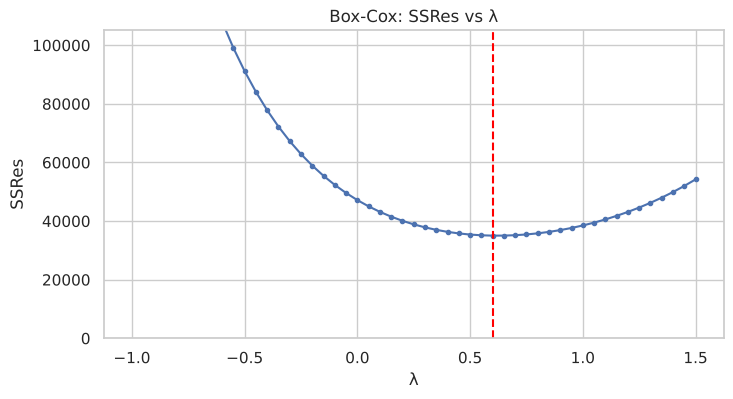

In [ ]:
from scipy import stats

# constante para statsmodels (igual que en el primer modelo)
X_train_mejor_const = sm.add_constant(X_train_mejor)
X_test_mejor_const = sm.add_constant(X_test_mejor)

# Box-Cox (sec. 5.4.1): se ajusta el modelo con y^λ para varios λ y se busca la menor SSRes
# y se escala con la media geométrica para que las SSRes se puedan comparar
y_punto = np.exp(np.mean(np.log(y_train)))

lambdas = np.round(np.arange(-1, 1.55, 0.05), 2)
ss_res = []
for l in lambdas:
    if l == 0:
        y_l = y_punto * np.log(y_train)
    else:
        y_l = (y_train**l - 1) / (l * y_punto**(l - 1))
    ss_res.append(sm.OLS(y_l, X_train_mejor_const).fit().ssr)

lam_opt = lambdas[np.argmin(ss_res)]
print("λ óptimo:", lam_opt)

plt.figure(figsize=(8, 4))
plt.plot(lambdas, ss_res, marker="o", markersize=3)
plt.axvline(lam_opt, color="red", linestyle="--")
plt.ylim(0, min(ss_res) * 3)
plt.title("Box-Cox: SSRes vs λ")
plt.xlabel("λ")
plt.ylabel("SSRes")
plt.show()

El λ óptimo salió de 0.6. El libro recomienda redondear a un valor fácil de interpretar, así que usamos **λ = 0.5, que es la raíz cuadrada de y**. En la gráfica la SSRes casi no cambia entre 0.5 y 0.6, y λ = 0 (logaritmo) da una SSRes mucho más grande, así que el log de y no conviene.

## Modelo 4: raíz cuadrada de y

In [ ]:
y_train_sqrt = np.sqrt(y_train)

resultado_sqrt = sm.OLS(y_train_sqrt, X_train_mejor_const).fit()
resultado_sqrt.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            resistencia   R-squared:                       0.819
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     451.0
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          1.84e-289
Time:                        19:34:36   Log-Likelihood:                -725.09
No. Observations:                 804   AIC:                             1468.
Df Residuals:                     795   BIC:                             1510.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  5.7531      0.021    272.051      0.000       5.712       5.795
cemento                1.1781      0.057     20.825      0.000       1.067       1.289
escoria_alto_horno     0.8153      0.057     14.376      0.000       0.704       0.927
ceniza_volante         0.5508      0.052     10.619      0.000       0.449       0.653
agua                  -0.2084      0.056     -3.742      0.000      -0.318      -0.099
superplastificante     0.0534      0.036      1.474      0.141      -0.018       0.125
agregado_grueso        0.1802      0.047      3.810      0.000       0.087       0.273
agregado_fino          0.2238      0.056      3.977      0.000       0.113       0.334
log_edad_dias          0.9117      0.022     41.786      0.000       0.869       0.955
==============================================================================
Omnibus:                        1.864   Durbin-Watson:                   1.903
Prob(Omnibus):                  0.394   Jarque-Bera (JB):                1.813
Skew:                          -0.035   Prob(JB):                        0.404
Kurtosis:                       3.222   Cond. No.                         8.60
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

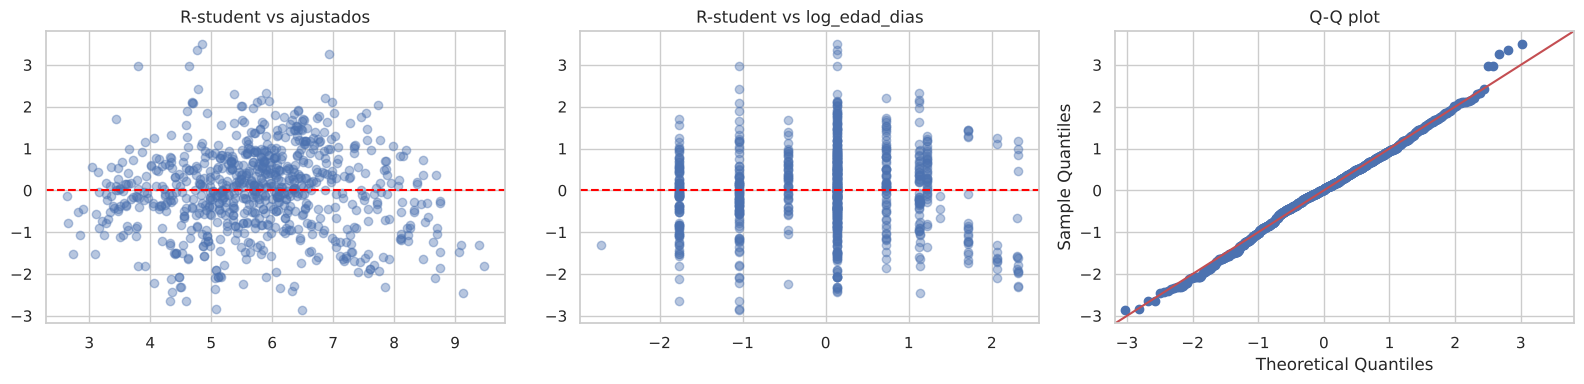

Breusch-Pagan p-valor: 1.5709909558340316e-08
Jarque-Bera p-valor: 0.40396939050489455


In [ ]:
rstudent_sqrt = resultado_sqrt.get_influence().resid_studentized_external

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(resultado_sqrt.fittedvalues, rstudent_sqrt, alpha=0.4)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("R-student vs ajustados")

axes[1].scatter(X_train_mejor["log_edad_dias"], rstudent_sqrt, alpha=0.4)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("R-student vs log_edad_dias")

sm.qqplot(rstudent_sqrt, line="45", ax=axes[2])
axes[2].set_title("Q-Q plot")

plt.tight_layout()
plt.show()

print("Breusch-Pagan p-valor:", het_breuschpagan(resultado_sqrt.resid, X_train_mejor_const)[1])
print("Jarque-Bera p-valor:", stats.jarque_bera(resultado_sqrt.resid).pvalue)

### Diagnóstico del Modelo 4

- **Normalidad:** se arregló. El Q-Q plot ya sigue la línea y Jarque-Bera ya no rechaza (p = 0.40); en el Modelo 3 rechazaba.
- **Varianza:** mejoró, pero Breusch-Pagan sigue rechazando (p = 1.6e-08, contra 1.9e-12 en el Modelo 3).
- `superplastificante` sigue sin ser significativo (p = 0.14).

In [ ]:
# las predicciones salen en raíz de MPa: se elevan al cuadrado para regresarlas a MPa ANTES de las métricas
pred_test_sqrt = resultado_sqrt.predict(X_test_mejor_const) ** 2

fila = pd.DataFrame([metricas(y_test, pred_test_sqrt, "Modelo 4: raíz de y")])
tabla_resultados = pd.concat([tabla_resultados, fila], ignore_index=True)
tabla_resultados = tabla_resultados.drop_duplicates(subset="Modelo").reset_index(drop=True)

tabla_resultados.round(3)

,Modelo,R²,RMSE (MPa),MAE (MPa)
0,Modelo 1: sin estandarizar,0.58,11.19,8.89
1,Modelo 2: estandarizado,0.58,11.19,8.89
2,Modelo 3: log edad (estandarizado),0.80,7.65,5.84
3,Modelo 4: raíz de y,0.80,7.71,5.76


### Evaluación del Modelo 4 en test

Las predicciones se regresaron a MPa (elevándolas al cuadrado) antes de calcular las métricas. Queda casi igual que el Modelo 3: R² = 0.80, RMSE = 7.71 MPa y MAE = 5.76 MPa. Transformar y no mejora la predicción, pero sí la normalidad de los residuos.

## Modelo 5: polinomial de grado 2

El Modelo 4 trata a cada ingrediente por separado, pero en una mezcla los ingredientes se afectan entre sí. Por eso agregamos los cuadrados y las interacciones entre las variables (cap. 7 del libro). Seguimos usando raíz de y y las X de `X_train_mejor`.

Para comparar con el Modelo 4 además usamos el PRESS (sec. 4.3), que mide qué tan bien predice el modelo cada dato cuando se ajusta sin ese dato.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# PRESS (sec. 4.3): error de predicción de cada dato cuando se ajusta el modelo sin ese dato
def press(resultado):
    h = resultado.get_influence().hat_matrix_diag
    return np.sum((resultado.resid / (1 - h)) ** 2)

# grado 2: cuadrados e interacciones de las variables de X_train_mejor
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly2 = pd.DataFrame(poly2.fit_transform(X_train_mejor), columns=poly2.get_feature_names_out(), index=X_train_mejor.index)
X_test_poly2 = pd.DataFrame(poly2.transform(X_test_mejor), columns=poly2.get_feature_names_out(), index=X_test_mejor.index)

X_train_poly2_const = sm.add_constant(X_train_poly2)
X_test_poly2_const = sm.add_constant(X_test_poly2)

resultado_poly2 = sm.OLS(y_train_sqrt, X_train_poly2_const).fit()

print("Número de variables:", X_train_poly2.shape[1])
print("R² ajustado:", round(resultado_poly2.rsquared_adj, 3))
print("Coeficientes no significativos (p > 0.05):", (resultado_poly2.pvalues.drop("const") > 0.05).sum())
print("Número de condición:", round(resultado_poly2.condition_number, 1))
print("PRESS Modelo 4:", round(press(resultado_sqrt), 1))
print("PRESS Modelo 5:", round(press(resultado_poly2), 1))

Número de variables: 44
R² ajustado: 0.892
Coeficientes no significativos (p > 0.05): 7
Número de condición: 138.8
PRESS Modelo 4: 293.6
PRESS Modelo 5: 185.6


In [ ]:
pred_test_poly2 = resultado_poly2.predict(X_test_poly2_const) ** 2   # regresar a MPa

fila = pd.DataFrame([metricas(y_test, pred_test_poly2, "Modelo 5: polinomial grado 2")])
tabla_resultados = pd.concat([tabla_resultados, fila], ignore_index=True)
tabla_resultados = tabla_resultados.drop_duplicates(subset="Modelo").reset_index(drop=True)

tabla_resultados.round(3)

,Modelo,R²,RMSE (MPa),MAE (MPa)
0,Modelo 1: sin estandarizar,0.58,11.19,8.89
1,Modelo 2: estandarizado,0.58,11.19,8.89
2,Modelo 3: log edad (estandarizado),0.80,7.65,5.84
3,Modelo 4: raíz de y,0.80,7.71,5.76
4,Modelo 5: polinomial grado 2,0.87,6.28,4.46


### Resultado del Modelo 5

Con 44 variables, el R² ajustado sube a 0.89 y el PRESS baja de 293.6 a 185.6. En test el RMSE baja de 7.71 a 6.28 MPa y el MAE de 5.76 a 4.46 MPa: es una mejora grande. Solo 7 coeficientes no son significativos y el número de condición es 139.

## Modelo 6: polinomial de grado 3

Como el grado 2 mejoró tanto, probamos el grado 3 (cubos e interacciones de tres variables).

In [ ]:
poly3 = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly3 = pd.DataFrame(poly3.fit_transform(X_train_mejor), columns=poly3.get_feature_names_out(), index=X_train_mejor.index)
X_test_poly3 = pd.DataFrame(poly3.transform(X_test_mejor), columns=poly3.get_feature_names_out(), index=X_test_mejor.index)

X_train_poly3_const = sm.add_constant(X_train_poly3)
X_test_poly3_const = sm.add_constant(X_test_poly3)

resultado_poly3 = sm.OLS(y_train_sqrt, X_train_poly3_const).fit()

print("Número de variables:", X_train_poly3.shape[1])
print("R² ajustado:", round(resultado_poly3.rsquared_adj, 3))
print("Coeficientes no significativos (p > 0.05):", (resultado_poly3.pvalues.drop("const") > 0.05).sum())
print("Número de condición:", round(resultado_poly3.condition_number, 1))
print("PRESS Modelo 6:", round(press(resultado_poly3), 1))
print("Leverage máximo:", round(resultado_poly3.get_influence().hat_matrix_diag.max(), 3))

Número de variables: 164
R² ajustado: 0.941
Coeficientes no significativos (p > 0.05): 111
Número de condición: 4849.3
PRESS Modelo 6: 237.8
Leverage máximo: 0.972


In [ ]:
pred_test_poly3 = resultado_poly3.predict(X_test_poly3_const) ** 2   # regresar a MPa

fila = pd.DataFrame([metricas(y_test, pred_test_poly3, "Modelo 6: polinomial grado 3")])
tabla_resultados = pd.concat([tabla_resultados, fila], ignore_index=True)
tabla_resultados = tabla_resultados.drop_duplicates(subset="Modelo").reset_index(drop=True)

tabla_resultados.round(3)

,Modelo,R²,RMSE (MPa),MAE (MPa)
0,Modelo 1: sin estandarizar,0.58,11.19,8.89
1,Modelo 2: estandarizado,0.58,11.19,8.89
2,Modelo 3: log edad (estandarizado),0.80,7.65,5.84
3,Modelo 4: raíz de y,0.80,7.71,5.76
4,Modelo 5: polinomial grado 2,0.87,6.28,4.46
5,Modelo 6: polinomial grado 3,0.90,5.46,3.58


### Resultado del Modelo 6

En test es todavía mejor: R² = 0.90, RMSE = 5.46 MPa y MAE = 3.58 MPa. Pero el modelo tiene problemas:

- Son 164 variables para 804 datos y **111 coeficientes no son significativos**.
- El número de condición sube de 139 a **4849**: hay multicolinealidad muy fuerte (cap. 9).
- **El PRESS empeora** (237.8 contra 185.6 del grado 2): al dejar fuera cada dato, el modelo predice peor que el de grado 2.
- Una observación tiene leverage de 0.97, o sea que el modelo prácticamente la memoriza.

Para controlar la multicolinealidad usamos Ridge (sec. 9.5 del libro), que le pone un freno a los coeficientes. Qué tan fuerte es el freno lo decide α, y lo escogemos con validación cruzada de 10 grupos dentro de train.

## Modelo 7: Ridge polinomial de grado 3

In [ ]:
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score

# probamos 50 valores de alpha y escogemos el mejor con validación cruzada de 10 grupos (solo train)
alphas = np.logspace(-3, 3, 50)
ridge3 = RidgeCV(alphas=alphas, cv=10).fit(X_train_poly3, y_train_sqrt)

print("alpha óptimo:", round(ridge3.alpha_, 4))
print("R² train:", round(r2_score(y_train, ridge3.predict(X_train_poly3) ** 2), 3))

pred_test_ridge3 = ridge3.predict(X_test_poly3) ** 2   # regresar a MPa

fila = pd.DataFrame([metricas(y_test, pred_test_ridge3, "Modelo 7: Ridge polinomial grado 3")])
tabla_resultados = pd.concat([tabla_resultados, fila], ignore_index=True)
tabla_resultados = tabla_resultados.drop_duplicates(subset="Modelo").reset_index(drop=True)

tabla_resultados.round(3)

alpha óptimo: 6.2506
R² train: 0.939


,Modelo,R²,RMSE (MPa),MAE (MPa)
0,Modelo 1: sin estandarizar,0.58,11.19,8.89
1,Modelo 2: estandarizado,0.58,11.19,8.89
2,Modelo 3: log edad (estandarizado),0.80,7.65,5.84
3,Modelo 4: raíz de y,0.80,7.71,5.76
4,Modelo 5: polinomial grado 2,0.87,6.28,4.46
5,Modelo 6: polinomial grado 3,0.90,5.46,3.58
6,Modelo 7: Ridge polinomial grado 3,0.90,5.40,3.62


### Resultado del Modelo 7

El α óptimo es 6.25. En test obtiene R² = 0.90, RMSE = 5.40 MPa y MAE = 3.62 MPa, prácticamente igual que el Modelo 6, pero con los coeficientes controlados. El R² de train es 0.94 y el de test 0.90: hay un poco de sobreajuste, pero es pequeño.

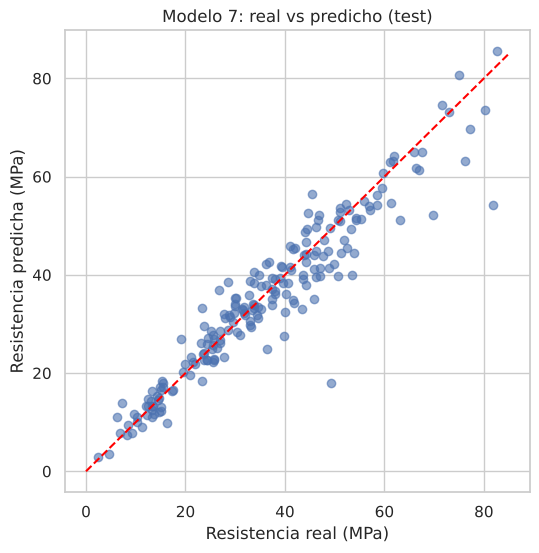

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test_ridge3, alpha=0.6)
plt.plot([0, 85], [0, 85], color="red", linestyle="--")
plt.title("Modelo 7: real vs predicho (test)")
plt.xlabel("Resistencia real (MPa)")
plt.ylabel("Resistencia predicha (MPa)")
plt.show()

## Modelo final

| Modelo | R² test | RMSE (MPa) | MAE (MPa) |
|---|---|---|---|
| 1 y 2: lineal | 0.58 | 11.19 | 8.90 |
| 3: log edad | 0.80 | 7.65 | 5.84 |
| 4: raíz de y | 0.80 | 7.71 | 5.76 |
| 5: polinomial grado 2 | 0.87 | 6.28 | 4.46 |
| 6: polinomial grado 3 | 0.90 | 5.46 | 3.58 |
| 7: Ridge polinomial grado 3 | 0.90 | 5.40 | 3.62 |

Escogemos el **Modelo 7 (Ridge polinomial de grado 3)**. Junto con el 6 es el que mejor predice en test, pero el Modelo 6 tiene multicolinealidad muy fuerte, muchos coeficientes no significativos y peor PRESS que el de grado 2. Ridge resuelve eso sin perder precisión, y su α se escogió con validación cruzada.

Como el Modelo 7 tiene 164 términos, sus coeficientes no se pueden interpretar uno por uno. Para **interpretar** usamos el Modelo 4: cemento, log de la edad, escoria y ceniza volante aumentan la resistencia, el agua la disminuye y superplastificante no es significativo. El efecto de la edad es grande en los primeros días y luego se aplana.

### Limitaciones
- La varianza no es del todo constante (Breusch-Pagan rechaza en los modelos 3 y 4).
- Los modelos se compararon usando el mismo conjunto de test.
- El Modelo 7 no se puede interpretar directamente y tiene algo de sobreajuste.
- `edad_dias` solo toma unos cuantos valores.
- El modelo solo sirve dentro del rango de mezclas del dataset.

### Conclusiones
El log de la edad fue la mejora más grande del modelo lineal (R² en test de 0.58 a 0.80). La raíz de y arregló la normalidad de los residuos. Agregar interacciones con modelos polinomiales bajó el error hasta 5.4 MPa, y Ridge permitió usar el grado 3 controlando la multicolinealidad. El modelo final tiene R² = 0.90 en datos que no se usaron para entrenar.